In [1]:
import numpy as np
import pandas as pd

In [2]:
ENTRY_AGE = 35
POLICY_TERM = 20
SUM_ASSURED = 1_000_000
INTEREST_RATE = 0.05

v = 1 / (1 + INTEREST_RATE)

INITIAL_EXPENSE = 1000
RENEWAL_EXPENSE = 200
COMMISSION_RATE = 0.10
PREMIUM_COLLECTION_EXPENSE = 50

In [3]:
ages = np.arange(ENTRY_AGE, ENTRY_AGE + POLICY_TERM)

qx_values = [
    0.0012 * (1.08 ** (age - ENTRY_AGE))
    for age in ages
]

mortality_table = pd.DataFrame({
    "Age": ages,
    "qx": qx_values
})

mortality_table

,Age,qx
0,35,0.001200
1,36,0.001296
2,37,0.001400
3,38,0.001512
4,39,0.001633
5,40,0.001763
6,41,0.001904
7,42,0.002057
8,43,0.002221
9,44,0.002399


In [4]:
mortality_table["px"] = 1 - mortality_table["qx"]

survival_probabilities = [1.0]

for px in mortality_table["px"]:
    survival_probabilities.append(
        survival_probabilities[-1] * px
    )

mortality_table["kpx"] = survival_probabilities[:-1]

mortality_table

,Age,qx,px,kpx
0,35,0.001200,0.998800,1.000000
1,36,0.001296,0.998704,0.998800
2,37,0.001400,0.998600,0.997506
3,38,0.001512,0.998488,0.996109
4,39,0.001633,0.998367,0.994604
5,40,0.001763,0.998237,0.992980
6,41,0.001904,0.998096,0.991229
7,42,0.002057,0.997943,0.989341
8,43,0.002221,0.997779,0.987307
9,44,0.002399,0.997601,0.985114


In [5]:
def calculate_benefit_epv(
    sum_assured,
    mortality_table,
    interest_rate
):
    v = 1 / (1 + interest_rate)

    benefit_epv = 0

    for k in range(len(mortality_table)):
        qx = mortality_table.loc[k, "qx"]
        kpx = mortality_table.loc[k, "kpx"]

        benefit_epv += (
            sum_assured
            * (v ** (k + 1))
            * kpx
            * qx
        )

    return benefit_epv


benefit_epv = calculate_benefit_epv(
    SUM_ASSURED,
    mortality_table,
    INTEREST_RATE
)

print(f"EPV of Benefits: ₹{benefit_epv:,.2f}")

EPV of Benefits: ₹29,618.88


In [6]:
def calculate_net_premium(
    benefit_epv,
    mortality_table,
    interest_rate
):
    v = 1 / (1 + interest_rate)

    premium_annuity_epv = 0

    for k in range(len(mortality_table)):
        kpx = mortality_table.loc[k, "kpx"]

        premium_annuity_epv += (
            (v ** k) * kpx
        )

    annual_premium = benefit_epv / premium_annuity_epv

    return annual_premium, premium_annuity_epv


annual_premium, premium_annuity_epv = calculate_net_premium(
    benefit_epv,
    mortality_table,
    INTEREST_RATE
)

print(f"Annual Net Premium: ₹{annual_premium:,.2f}")
print(f"Premium Annuity EPV: {premium_annuity_epv:.4f}")

Annual Net Premium: ₹2,298.37
Premium Annuity EPV: 12.8869


In [7]:
def calculate_reserves(
    entry_age,
    policy_term,
    sum_assured,
    annual_premium,
    mortality_table,
    interest_rate
):
    v = 1 / (1 + interest_rate)

    reserves = []

    for t in range(policy_term + 1):

        remaining_term = policy_term - t

        future_benefits_epv = 0
        future_premiums_epv = 0
        survival_probability = 1.0

        for k in range(remaining_term):

            qx = mortality_table.loc[t + k, "qx"]
            px = 1 - qx

            future_benefits_epv += (
                sum_assured
                * (v ** (k + 1))
                * survival_probability
                * qx
            )

            future_premiums_epv += (
                (v ** k) * survival_probability
            )

            survival_probability *= px

        reserve = (
            future_benefits_epv
            - annual_premium * future_premiums_epv
        )

        reserves.append({
            "Duration": t,
            "Age": entry_age + t,
            "Remaining_Term": remaining_term,
            "Reserve": reserve
        })

    return pd.DataFrame(reserves)


reserve_df = calculate_reserves(
    ENTRY_AGE,
    POLICY_TERM,
    SUM_ASSURED,
    annual_premium,
    mortality_table,
    INTEREST_RATE
)

reserve_df

,Duration,Age,Remaining_Term,Reserve
0,0,35,20,0.000000
1,1,36,19,1214.745898
2,2,37,18,2395.876452
3,3,38,17,3534.225262
4,4,39,16,4619.553497
5,5,40,15,5640.441133
6,6,41,14,6584.166862
7,7,42,13,7436.575313
8,8,43,12,8181.930027
9,9,44,11,8802.750412


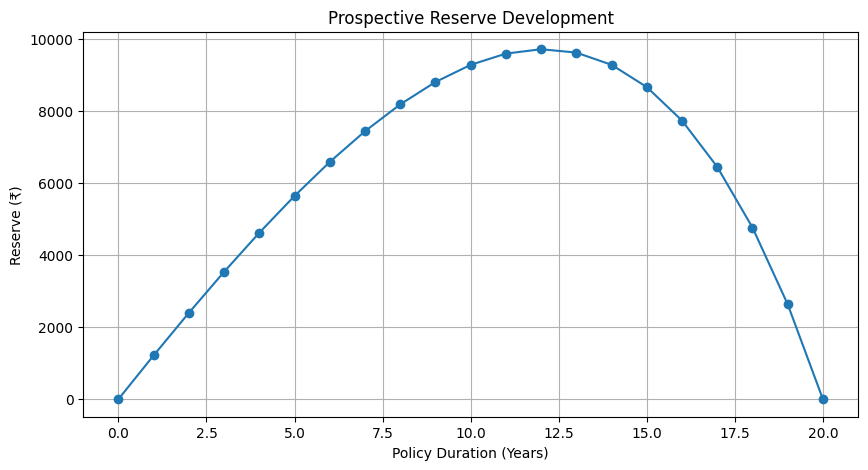

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    reserve_df["Duration"],
    reserve_df["Reserve"],
    marker="o"
)

plt.title("Prospective Reserve Development")
plt.xlabel("Policy Duration (Years)")
plt.ylabel("Reserve (₹)")
plt.grid(True)

plt.show()

In [ ]:
print("TERM ASSURANCE MODEL SUMMARY")
print("-" * 100)

print(input(f"Entry Age: {ENTRY_AGE}"))
print(f"Policy Term: {POLICY_TERM} years")
print(f"Sum Assured: ₹{SUM_ASSURED:,.2f}")
print(f"Interest Rate: {INTEREST_RATE:.2%}")
print(f"Annual Net Premium: ₹{annual_premium:,.2f}")

print(f"\nInitial Reserve: ₹{reserve_df.iloc[0]['Reserve']:,.2f}")
print(f"Final Reserve: ₹{reserve_df.iloc[-1]['Reserve']:,.2f}")

TERM ASSURANCE MODEL SUMMARY
----------------------------------------------------------------------------------------------------
